In [24]:
!pip install catboost

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler , StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [26]:
df = pd.read_csv(r"/content/diabetes_patients_10000_full.csv")

In [27]:
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [28]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,10000.00000,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,5000.50000,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,2886.89568,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,1.00000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2500.75000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5000.50000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7500.25000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.00000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [29]:
df.isnull().sum()

,0
Patient_ID,0
Age,14
Gender,40
Blood_Sugar_Level,53
Creatinine,56
BMI,51
Urea,51
Cholesterol,32
HbA1c,0
Class,0


In [30]:
df.dropna(inplace=True)

In [31]:
 df.duplicated().sum()



np.int64(0)

In [32]:
df["Gender"] = df["Gender"].map({
    "Male": 1,
    "Female": 0
})

In [33]:
X = df.drop(columns=["Patient_ID", "Class"])
y = df["Class"]

In [34]:
y = y.map({
    'Non-Diabetic': 0,
    'Diabetic': 1
})

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [36]:
num_cols = [
    "Age",
    "Blood_Sugar_Level",
    "Creatinine",
    "BMI",
    "Urea",
    "Cholesterol",
    "HbA1c"
]
cat_cols = X.select_dtypes(
    include=["object", "category", "bool"])

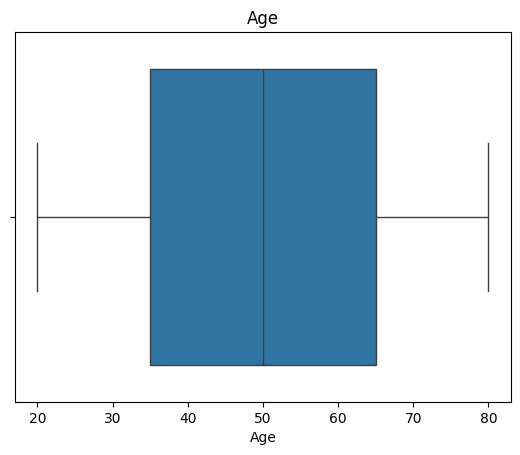

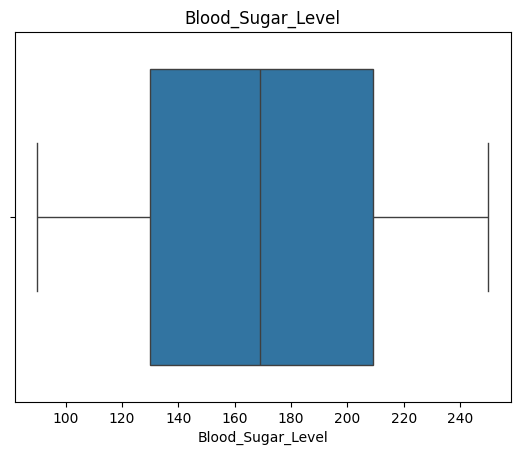

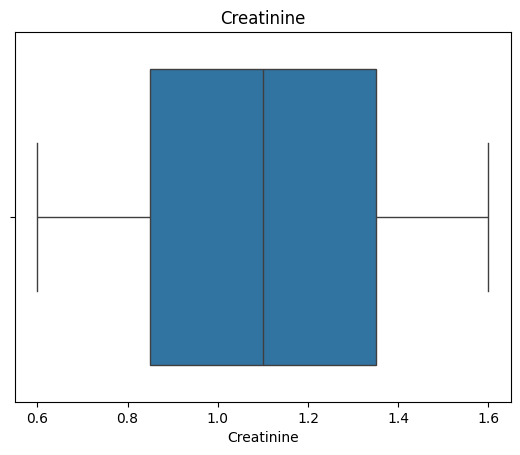

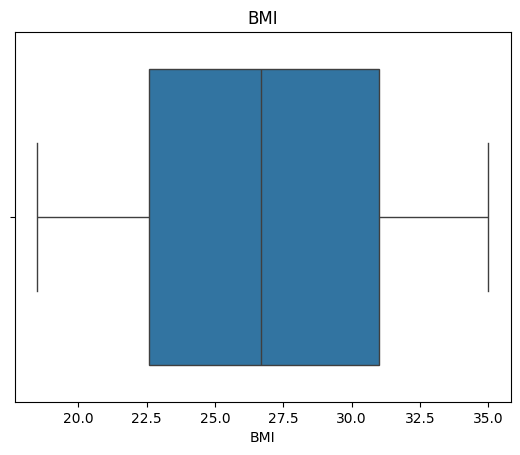

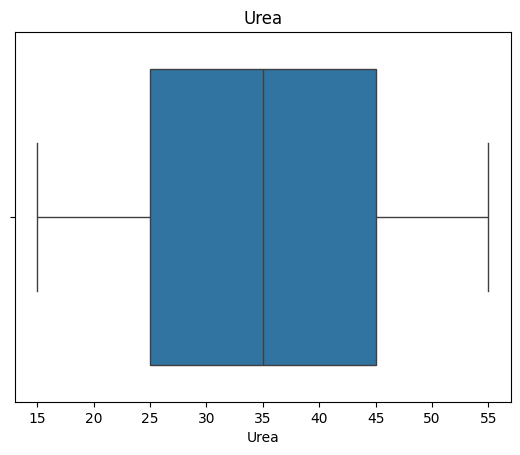

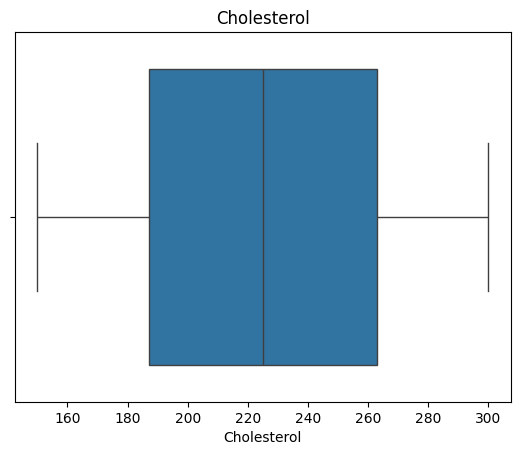

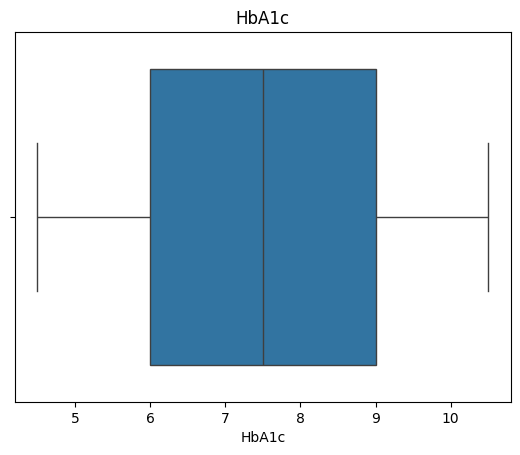

In [37]:
for col in num_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

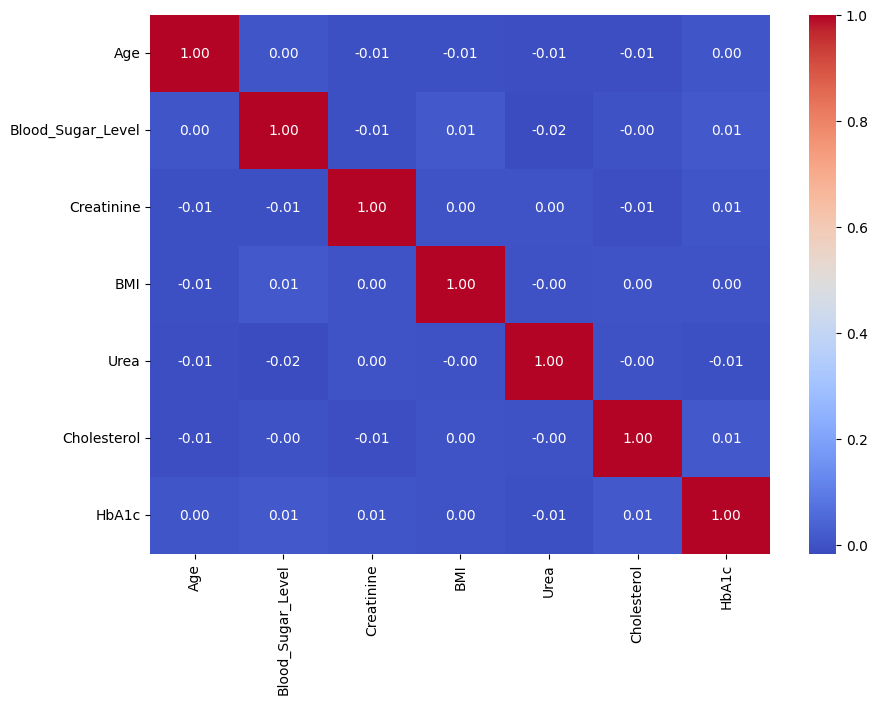

In [38]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

In [39]:
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [40]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[ 141   29]
 [  18 1799]]


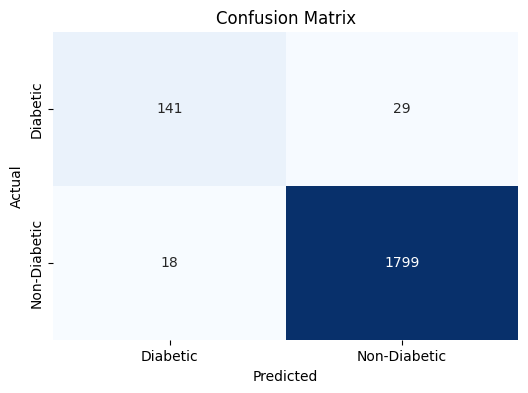


Classification Report:

              precision    recall  f1-score   support

    Diabetic       0.89      0.83      0.86       170
Non-Diabetic       0.98      0.99      0.99      1817

    accuracy                           0.98      1987
   macro avg       0.94      0.91      0.92      1987
weighted avg       0.98      0.98      0.98      1987

ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


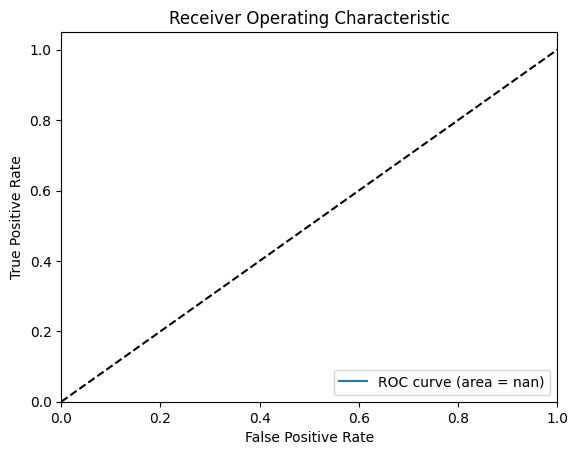

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


PR AUC: 0.0


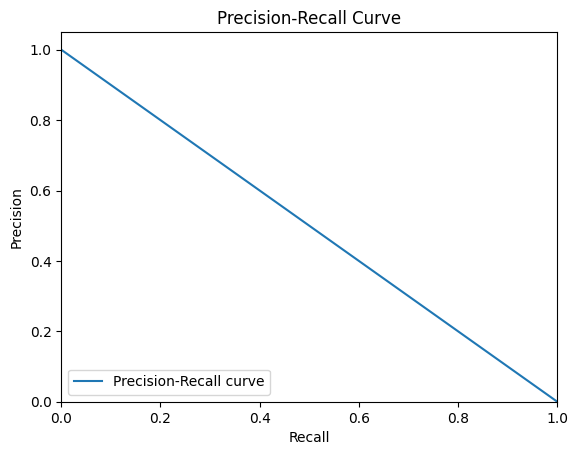

  8%|▊         | 1/13 [00:00<00:08,  1.41it/s]


Confusion Matrix:
 [[ 130   40]
 [  23 1794]]


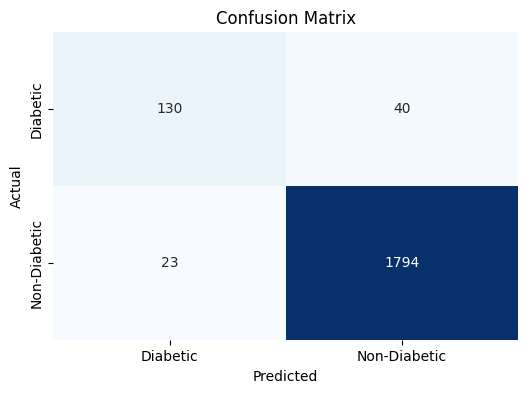


Classification Report:

              precision    recall  f1-score   support

    Diabetic       0.85      0.76      0.80       170
Non-Diabetic       0.98      0.99      0.98      1817

    accuracy                           0.97      1987
   macro avg       0.91      0.88      0.89      1987
weighted avg       0.97      0.97      0.97      1987

ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


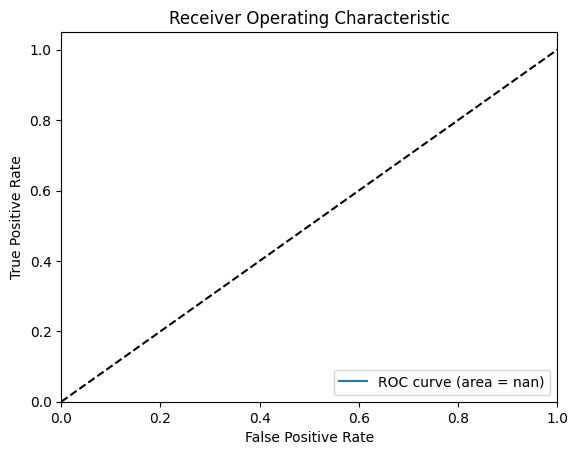

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


PR AUC: 0.0


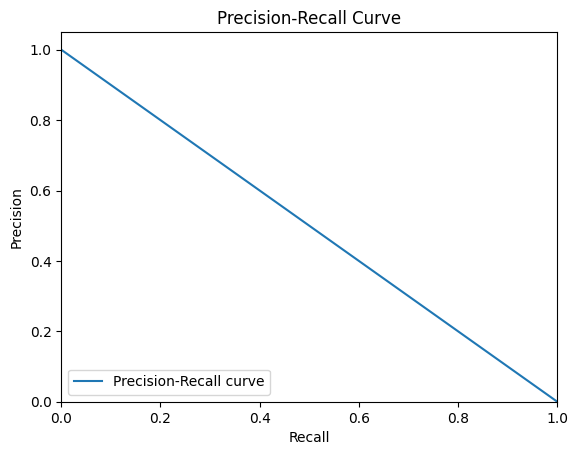

 15%|█▌        | 2/13 [00:02<00:13,  1.21s/it]


Confusion Matrix:
 [[ 145   25]
 [  10 1807]]


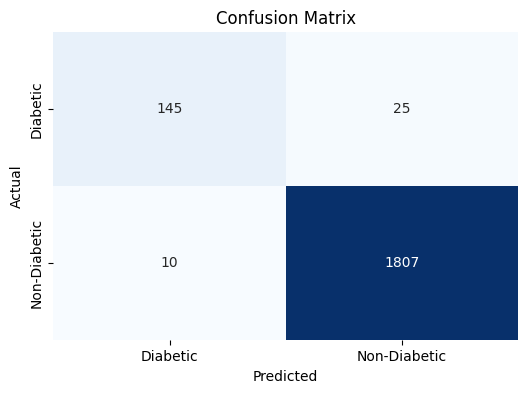


Classification Report:

              precision    recall  f1-score   support

    Diabetic       0.94      0.85      0.89       170
Non-Diabetic       0.99      0.99      0.99      1817

    accuracy                           0.98      1987
   macro avg       0.96      0.92      0.94      1987
weighted avg       0.98      0.98      0.98      1987



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


ROC-AUC: nan


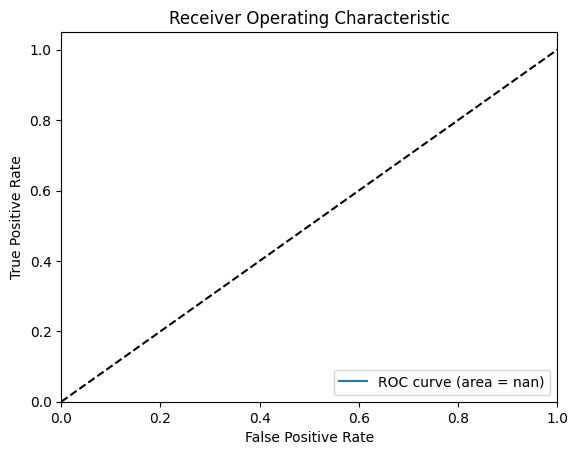

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


PR AUC: 0.0


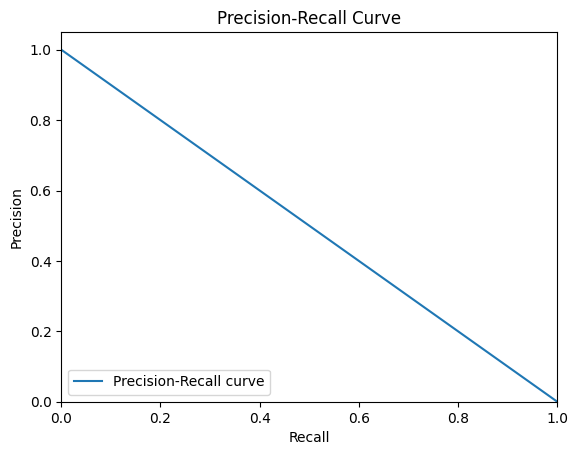

 23%|██▎       | 3/13 [00:08<00:37,  3.72s/it]


Confusion Matrix:
 [[ 170    0]
 [   0 1817]]


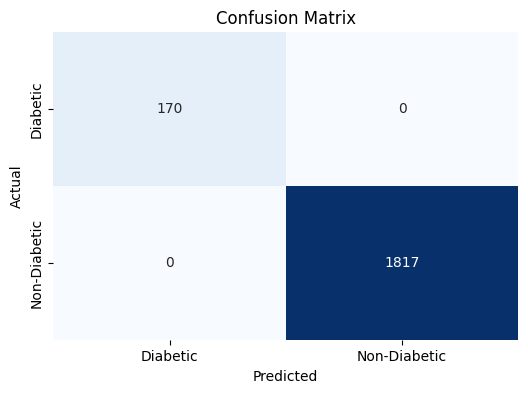

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(



Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: nan


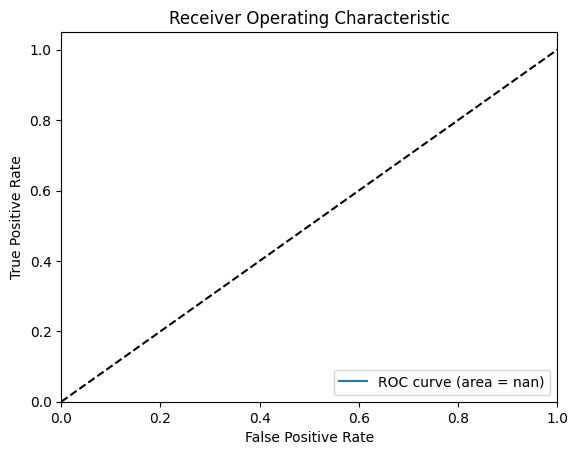

PR AUC: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


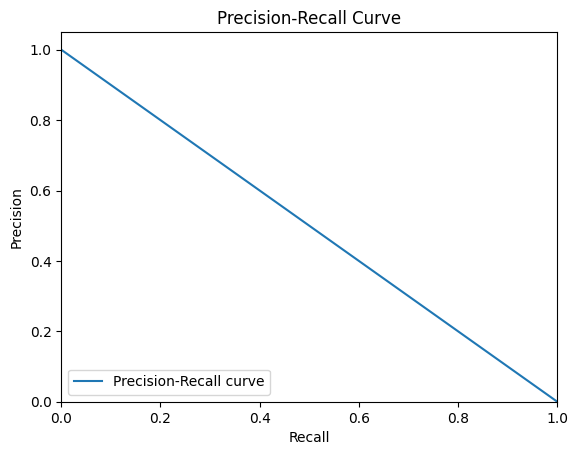

 31%|███       | 4/13 [00:09<00:21,  2.42s/it]


Confusion Matrix:
 [[ 152   18]
 [   0 1817]]


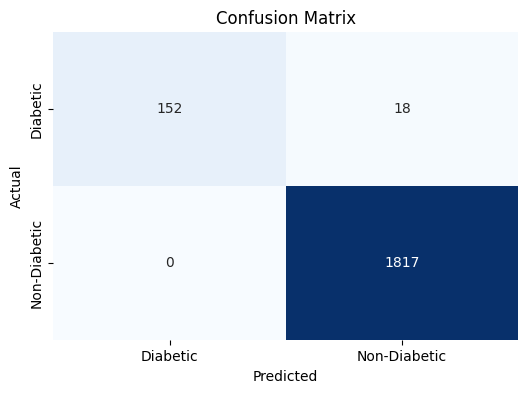

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(



Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      0.89      0.94       170
Non-Diabetic       0.99      1.00      1.00      1817

    accuracy                           0.99      1987
   macro avg       1.00      0.95      0.97      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: nan


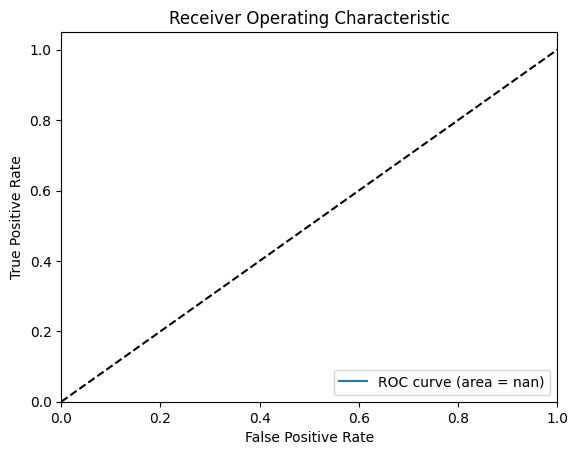

PR AUC: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


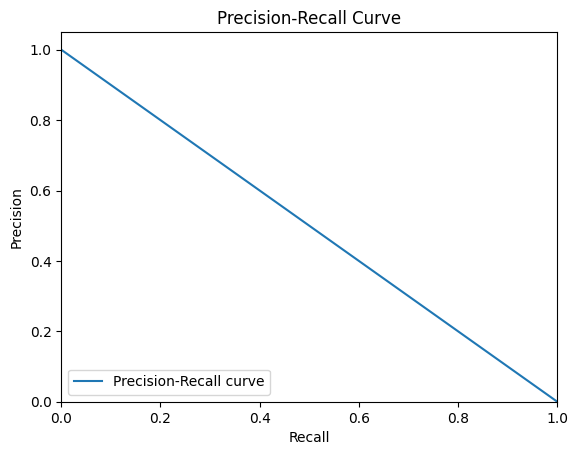

 38%|███▊      | 5/13 [00:09<00:13,  1.72s/it]


Confusion Matrix:
 [[ 170    0]
 [   0 1817]]


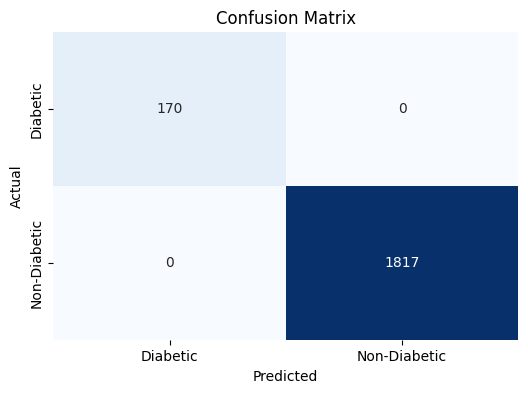


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


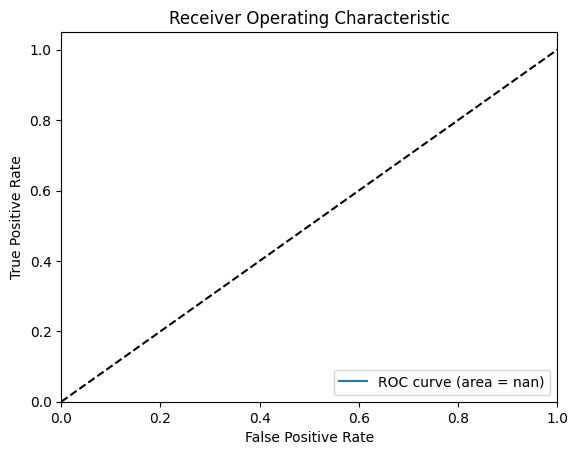

PR AUC: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


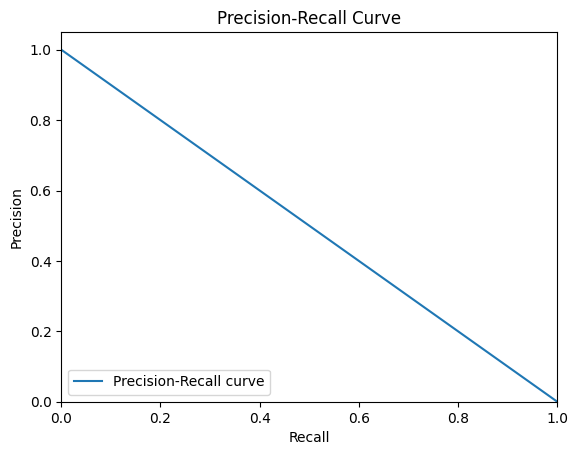

 46%|████▌     | 6/13 [00:10<00:10,  1.45s/it]


Confusion Matrix:
 [[ 147   23]
 [   0 1817]]


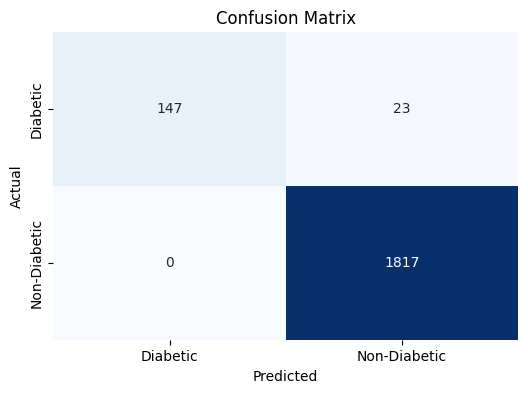


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      0.86      0.93       170
Non-Diabetic       0.99      1.00      0.99      1817

    accuracy                           0.99      1987
   macro avg       0.99      0.93      0.96      1987
weighted avg       0.99      0.99      0.99      1987

ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


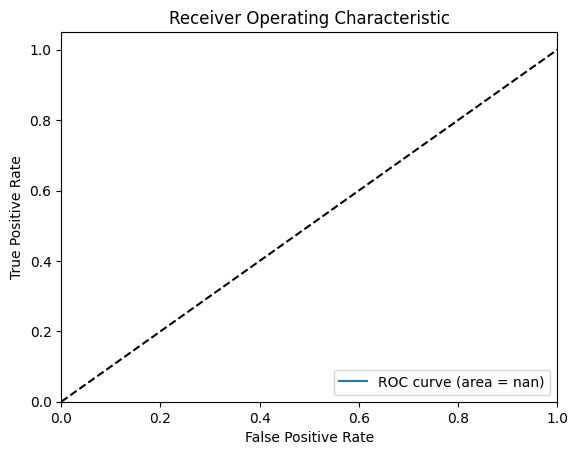

PR AUC: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


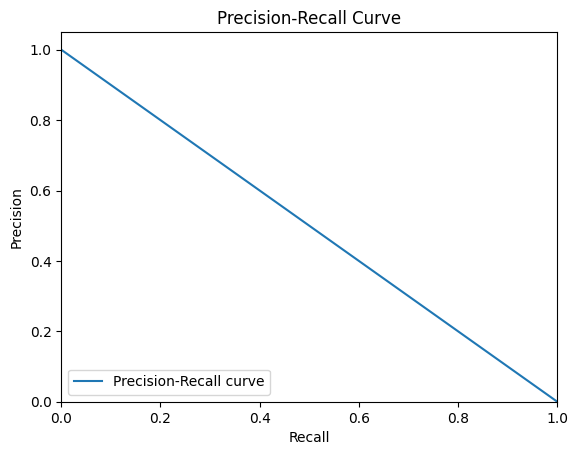

 54%|█████▍    | 7/13 [00:11<00:07,  1.29s/it]


Confusion Matrix:
 [[ 170    0]
 [   0 1817]]


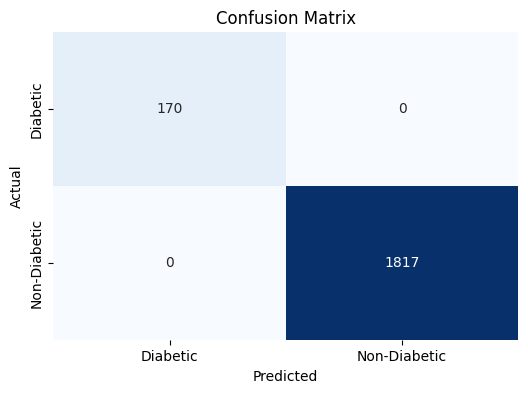


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


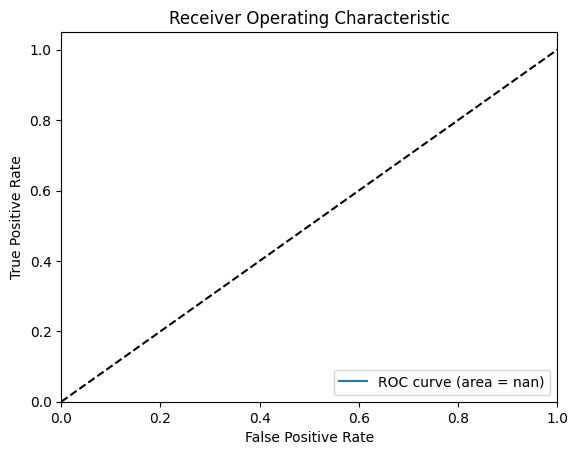

PR AUC: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


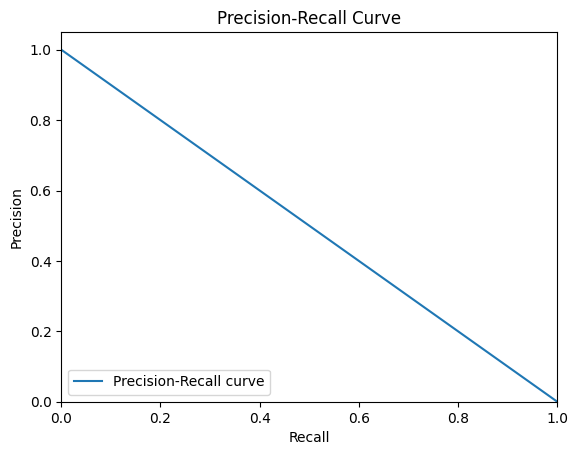

 62%|██████▏   | 8/13 [00:12<00:05,  1.15s/it]


Confusion Matrix:
 [[ 170    0]
 [   0 1817]]


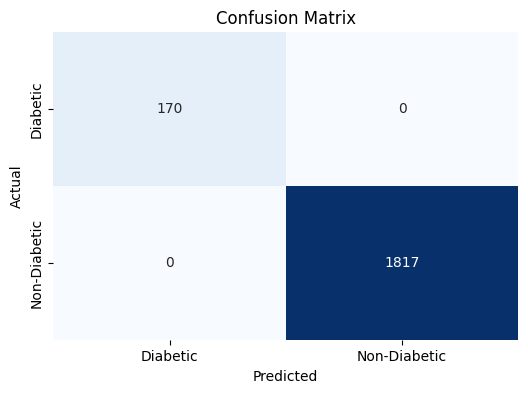


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


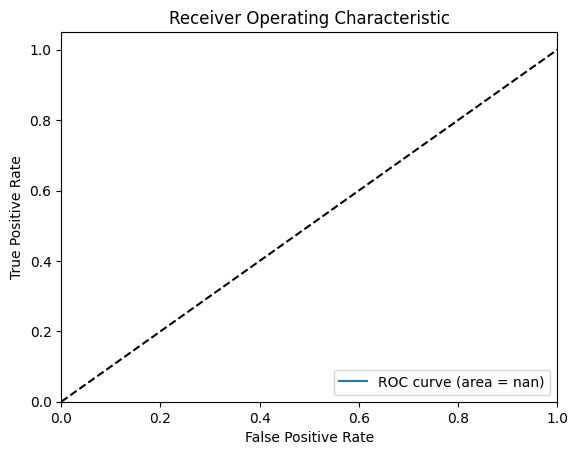

PR AUC: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


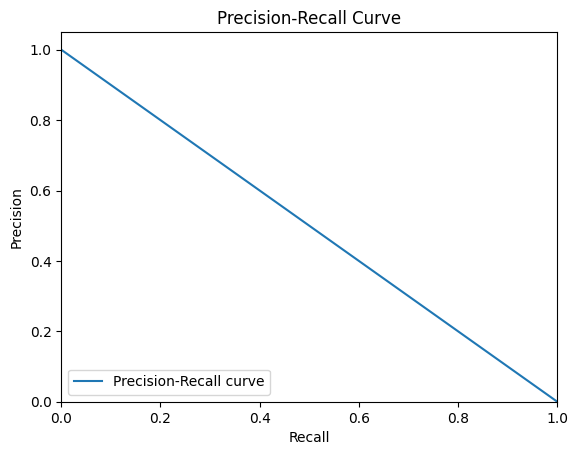

 69%|██████▉   | 9/13 [00:13<00:04,  1.13s/it]


Confusion Matrix:
 [[ 170    0]
 [   0 1817]]


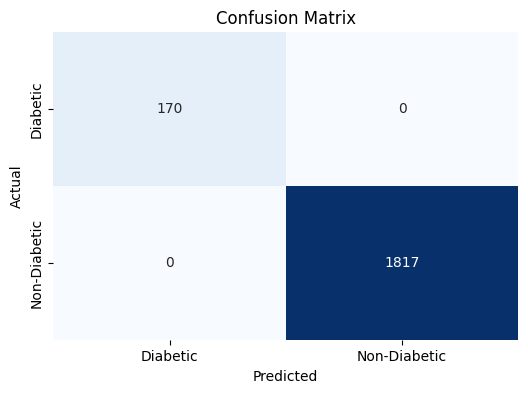


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


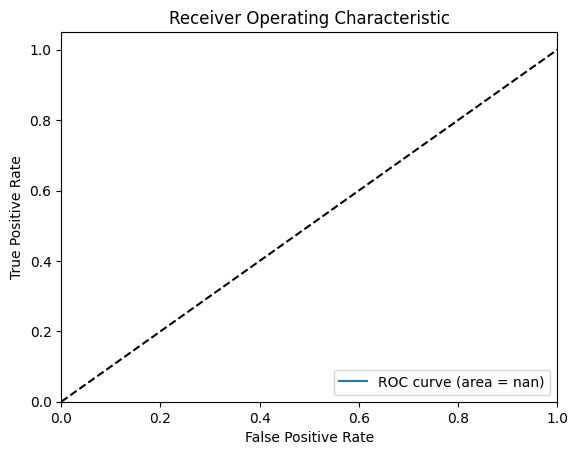

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


PR AUC: 0.0


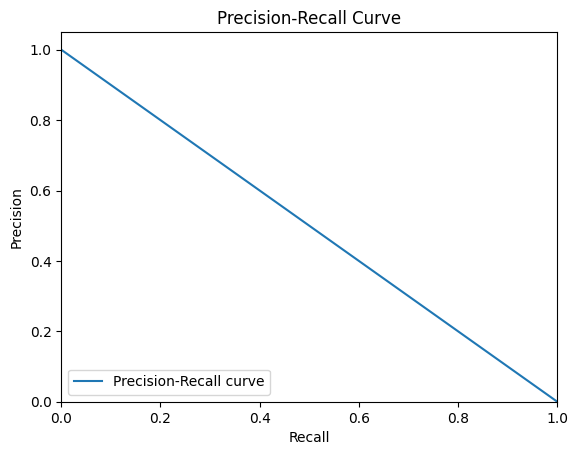

 77%|███████▋  | 10/13 [00:14<00:02,  1.02it/s]


Confusion Matrix:
 [[ 170    0]
 [   0 1817]]


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:52:23] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


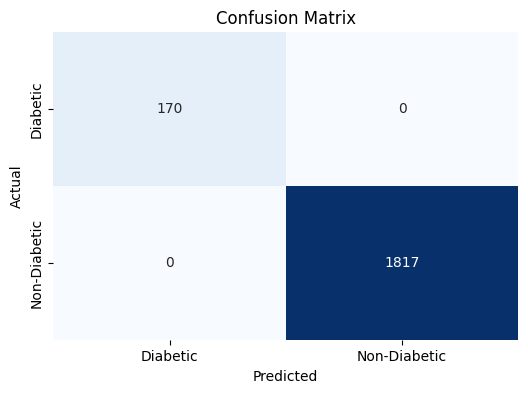

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(



Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: nan


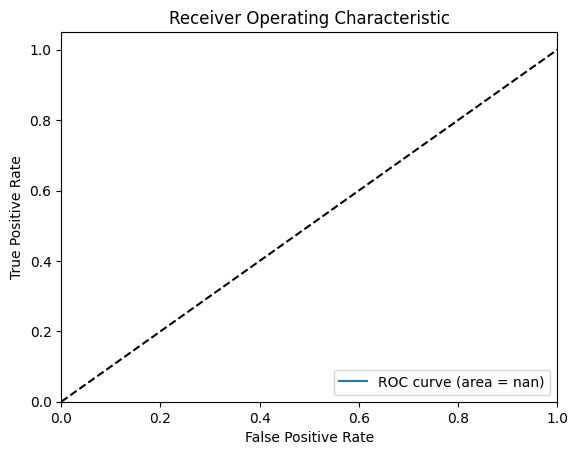

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


PR AUC: 0.0


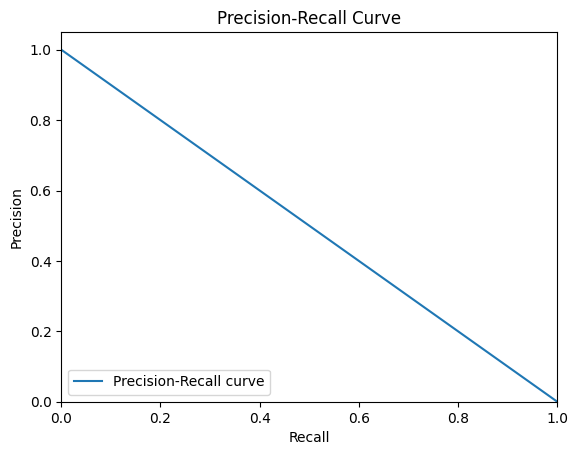

 85%|████████▍ | 11/13 [00:14<00:01,  1.16it/s]


Confusion Matrix:
 [[ 170    0]
 [   0 1817]]


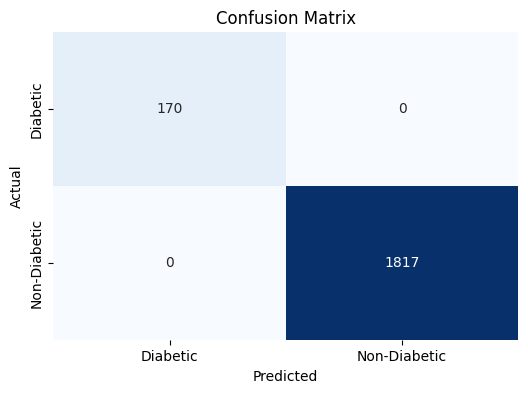


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


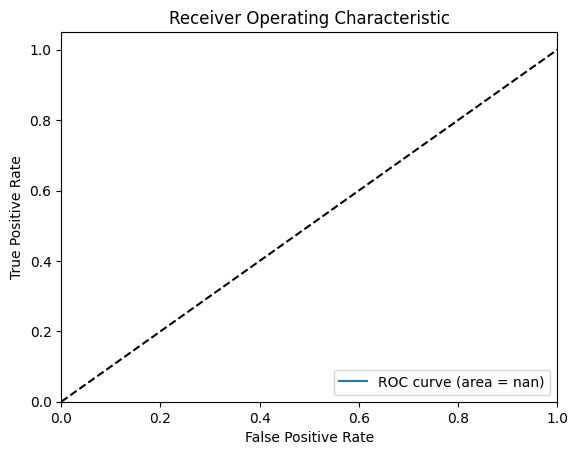

PR AUC: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


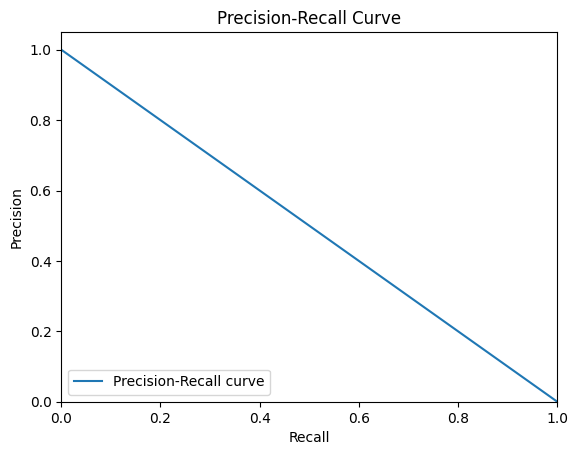

 92%|█████████▏| 12/13 [00:18<00:01,  1.69s/it]

[LightGBM] [Info] Number of positive: 7266, number of negative: 679
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001279 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 751
[LightGBM] [Info] Number of data points in the train set: 7945, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.914537 -> initscore=2.370340
[LightGBM] [Info] Start training from score 2.370340
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

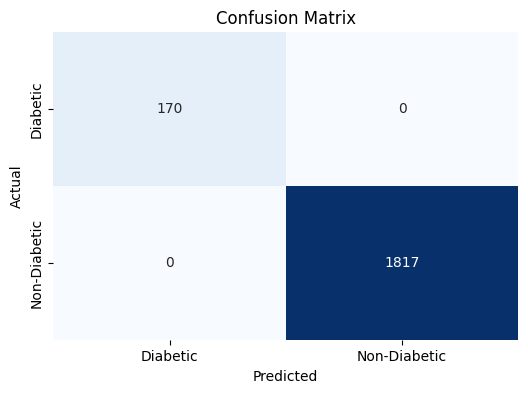


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


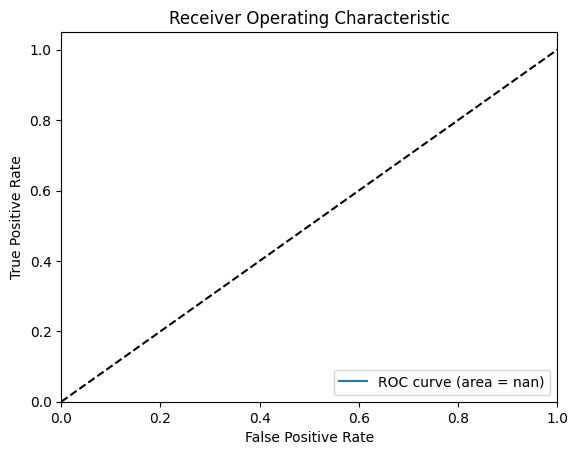

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


PR AUC: 0.0


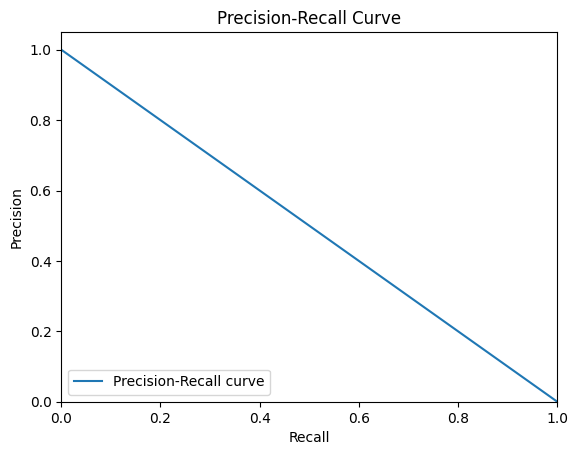

100%|██████████| 13/13 [00:19<00:00,  1.49s/it]


In [23]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
                xticklabels=['Diabetic', 'Non-Diabetic'],
                yticklabels=['Diabetic', 'Non-Diabetic'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(
        y_test, test_pred,
        target_names=['Diabetic', 'Non-Diabetic'],
        zero_division=0
    ))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    y_test_binary = (y_test == 'Non-Diabetic').astype(int)

    roc_auc = roc_auc_score(y_test_binary, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test_binary, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test_binary, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(
        y_test_binary, y_pred_prob
    )
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:56:20] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[ 170    0]
 [   0 1817]]


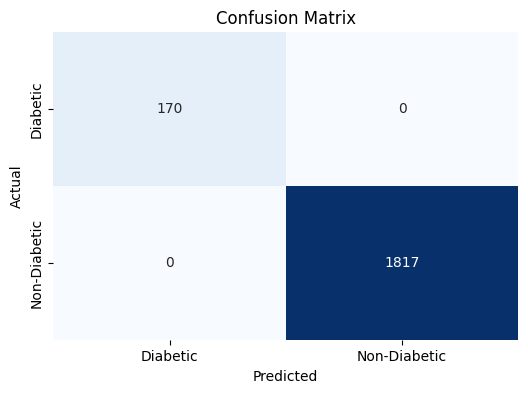


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


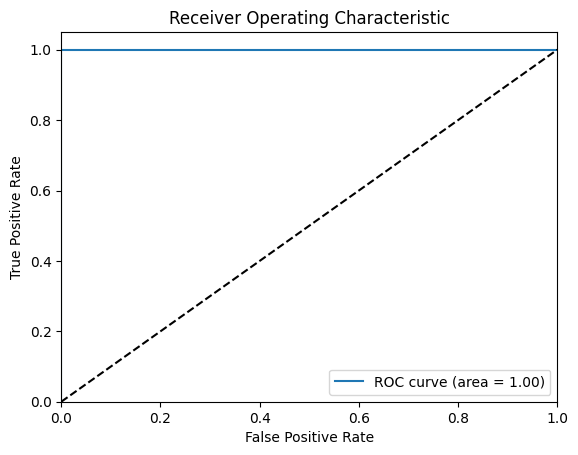

PR AUC: 1.0


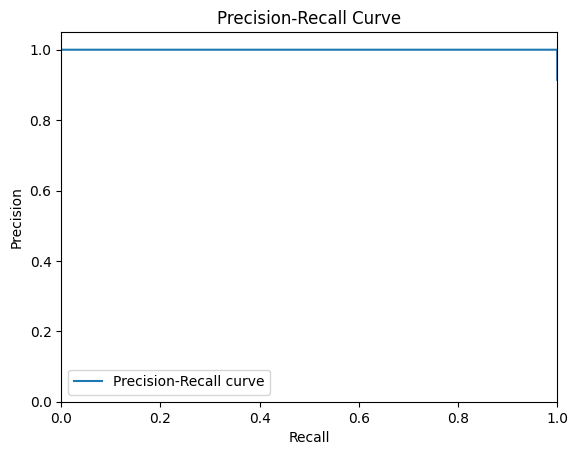

In [43]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Diabetic','Non-Diabetic']
            ,yticklabels=['Diabetic','Non-Diabetic'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Diabetic','Non-Diabetic'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}


Confusion Matrix:
 [[ 170    0]
 [   0 1817]]


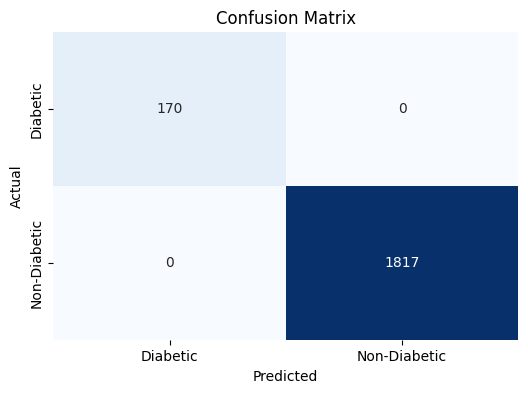


Classification Report:

              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00       170
Non-Diabetic       1.00      1.00      1.00      1817

    accuracy                           1.00      1987
   macro avg       1.00      1.00      1.00      1987
weighted avg       1.00      1.00      1.00      1987

ROC-AUC: 1.0


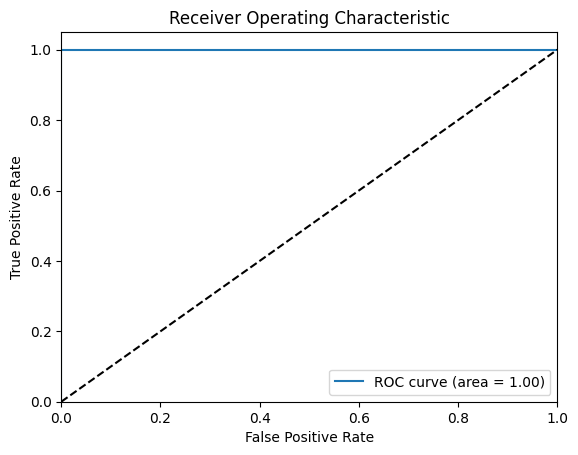

PR AUC: 1.0


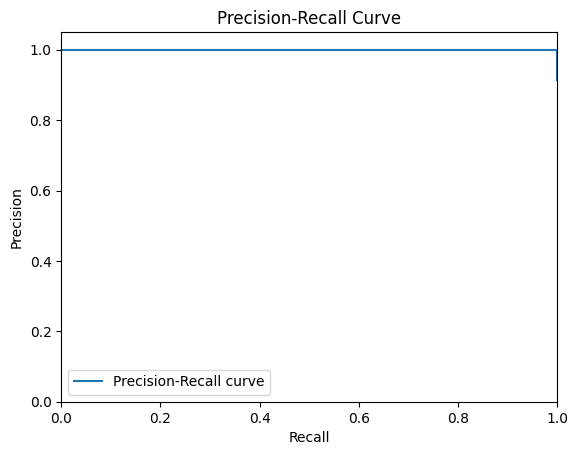

In [45]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),
    ],
    final_estimator=XGBClassifier(n_estimators=2000),
    stack_method="predict_proba",
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

class_names = ['Diabetic', 'Non-Diabetic']

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
             xticklabels=class_names,
             yticklabels=class_names)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(
    y_test, stack_auto_test_pred,
    target_names=class_names,
    zero_division=0
))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [46]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Decision Tree,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.0
Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.0
CatBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.0
XGBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.0
Hist Gradient Boosting,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.0
Gradient Boosting,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.0
AdaBoost,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.0
Voting Classifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.0
LightGBM,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,0.0
Stacking Classifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.0


<Axes: >

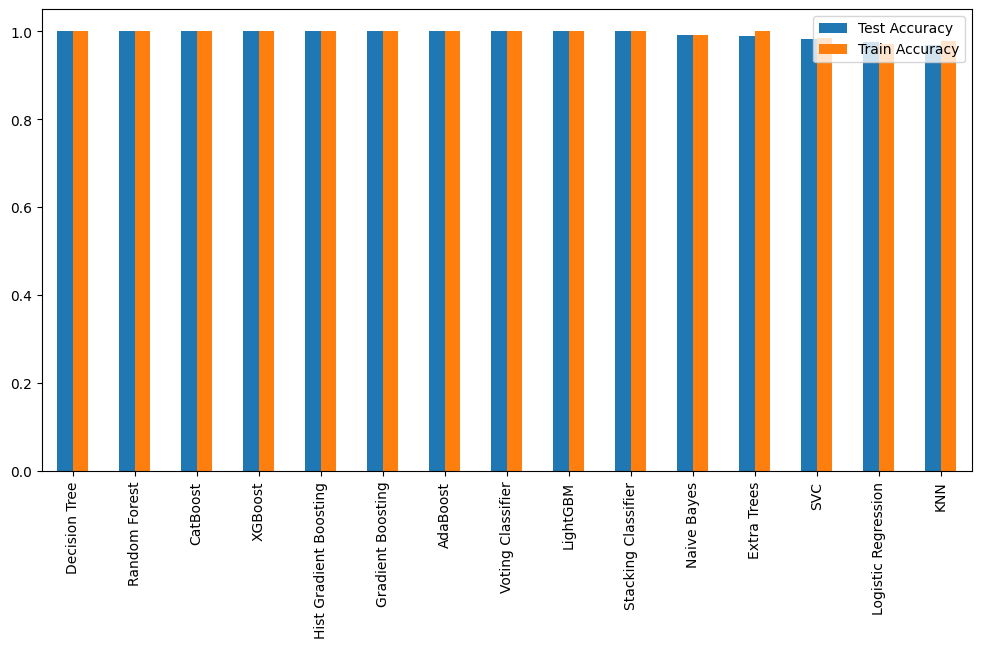

In [47]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

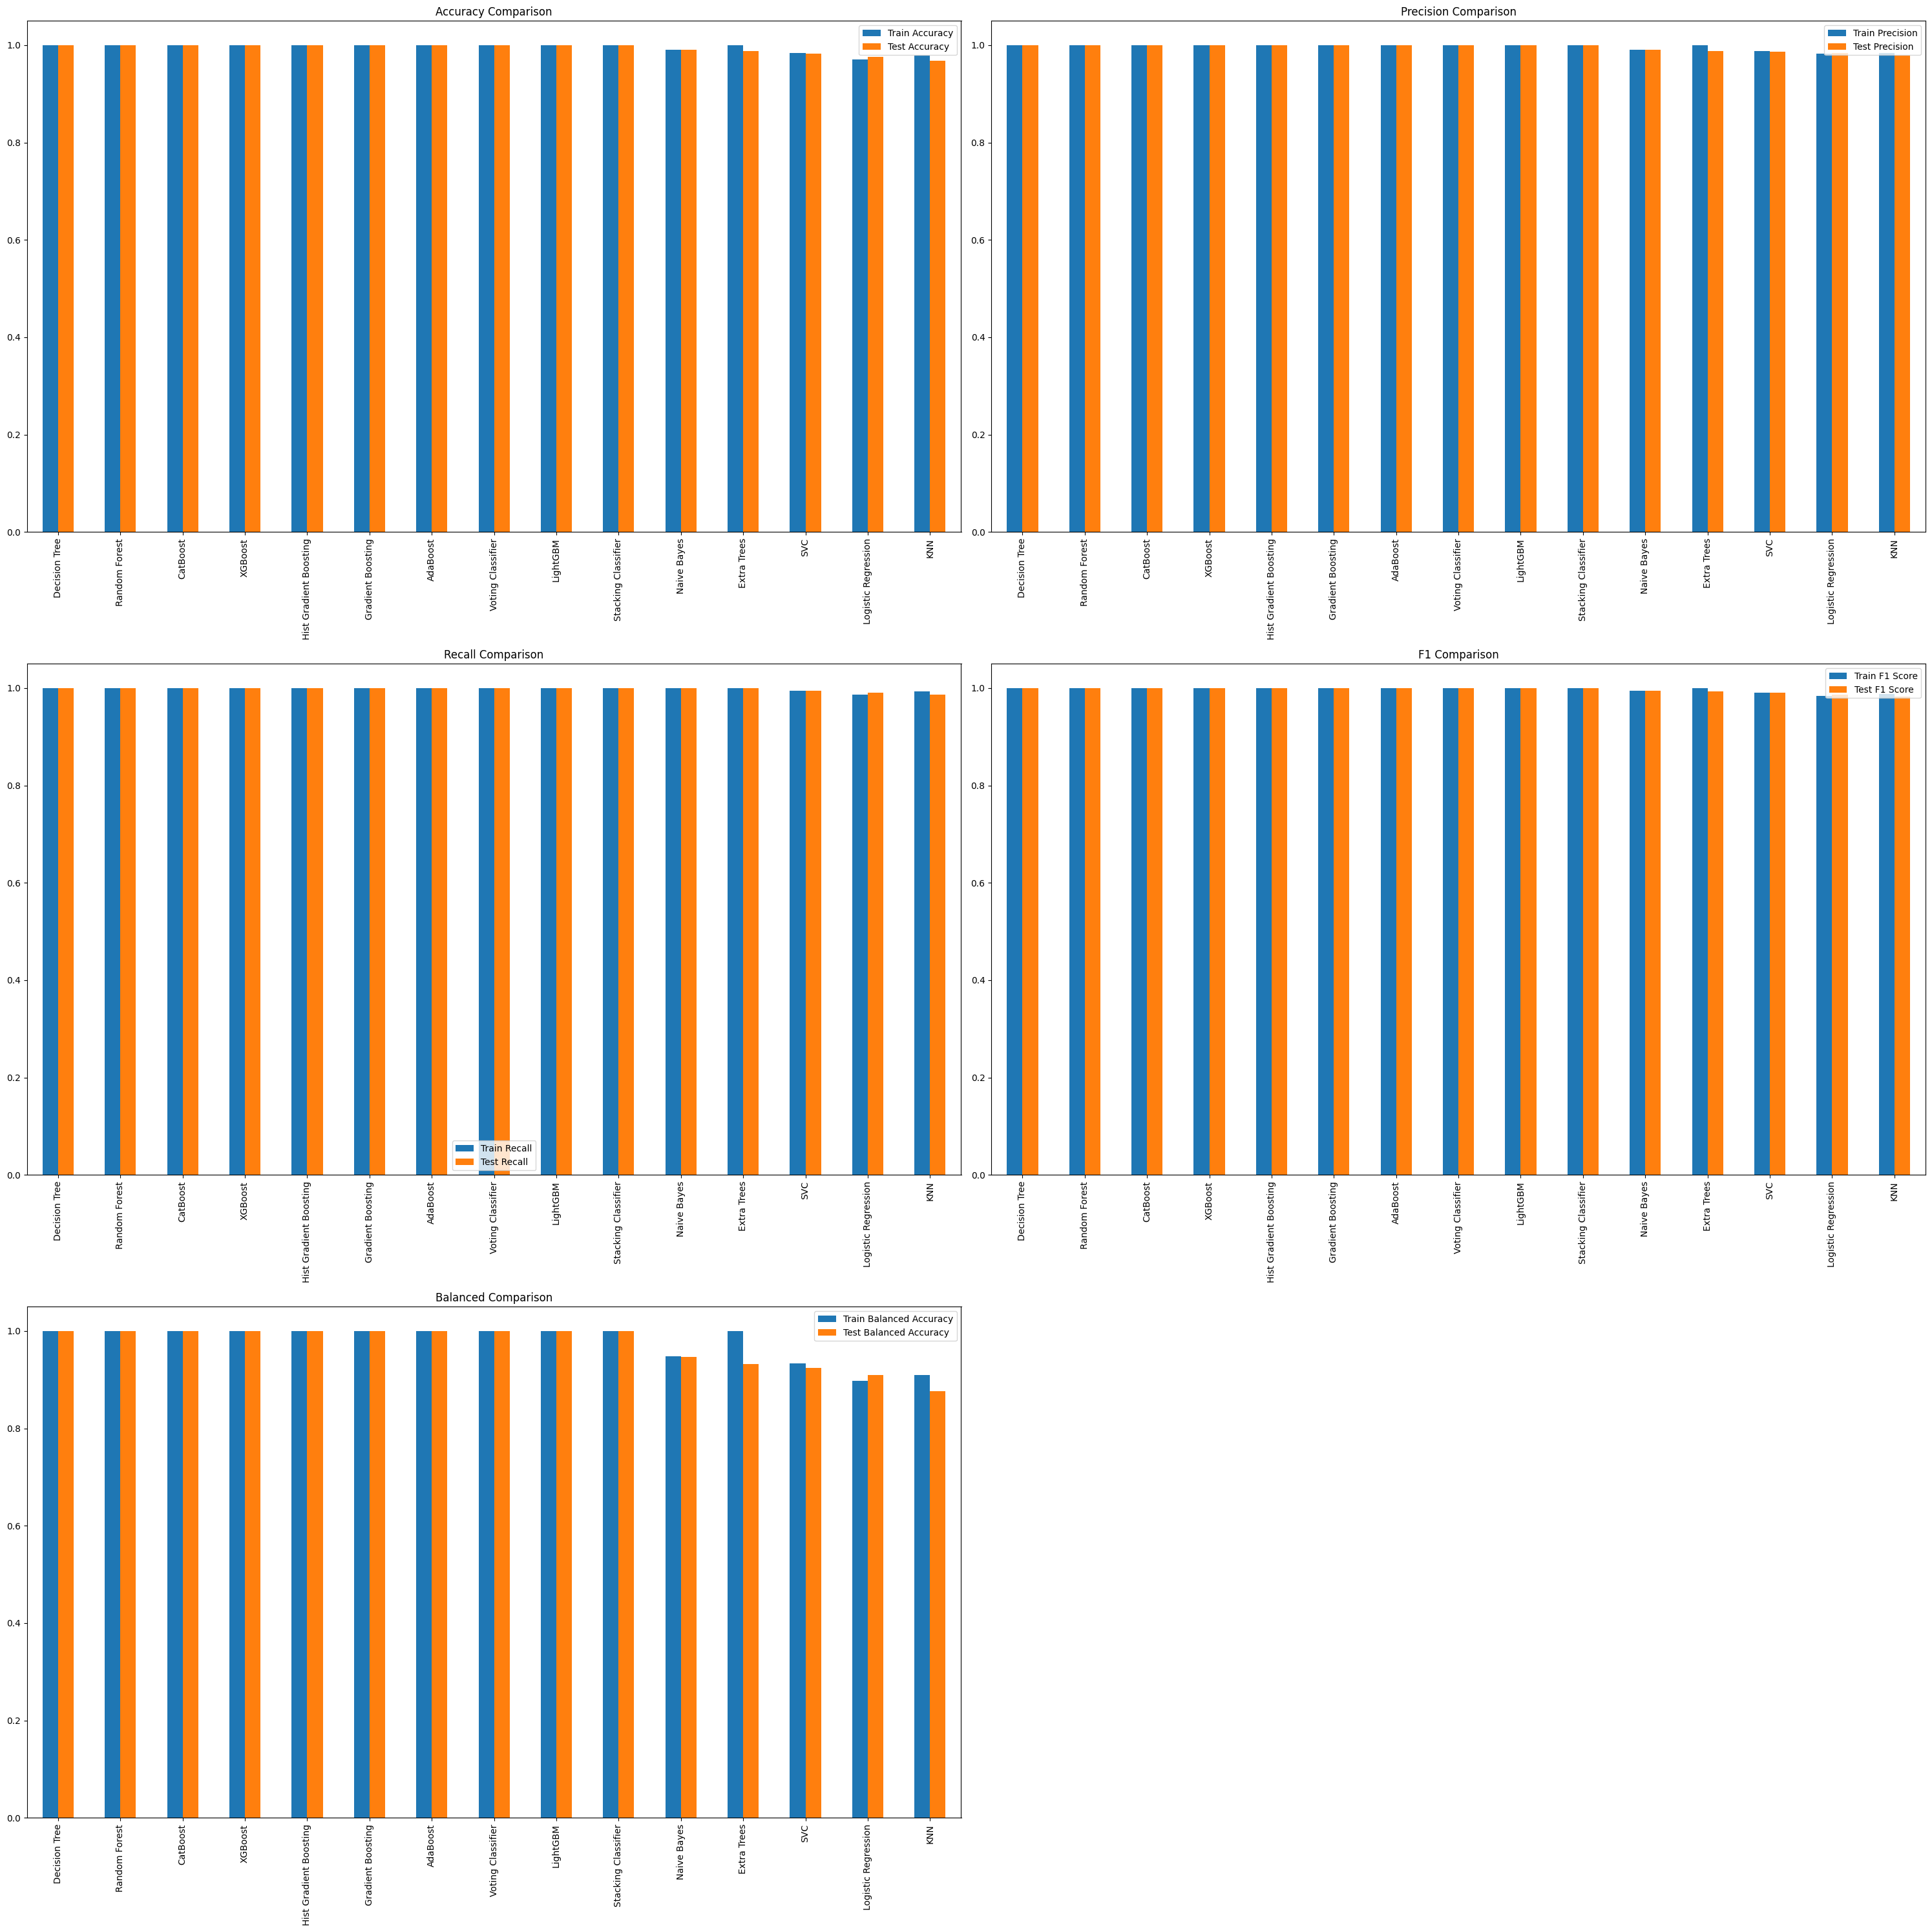

In [48]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()